In [3]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
appointment_df = pd.read_csv("apollo_appointments_fact.csv")
doctor_df = pd.read_csv("apollo_doctors_dim.csv")


## Inspecting data frames


In [11]:
appointment_df


,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,insurance_coverage,insurance_provider,insurance_covered_amount,patient_out_of_pocket,revenue_realized,payment_mode,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,No,NaN,0,2700,2700,UPI,11.0,40.0,4.8,84.2
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,No,NaN,0,1400,1400,UPI,21.0,18.0,4.1,64.5
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,No,NaN,0,600,600,Net Banking,6.0,6.0,5.0,75.6
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,No,NaN,0,1275,1275,UPI,2.0,25.0,4.4,68.6
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,No,NaN,0,1700,1700,Cash,7.0,13.0,3.5,67.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74995,APPT5074996,PAT124687,DOC1215,2024-02-04,Sunday,6,2,Q1,2024,16,...,No,NaN,0,700,700,Credit Card,0.0,27.0,4.2,78.4
74996,APPT5074997,PAT135901,DOC1236,2022-03-18,Friday,4,3,Q1,2022,9,...,No,NaN,0,1020,1020,Debit Card,4.0,26.0,3.7,72.2
74997,APPT5074998,PAT123568,DOC1163,2022-08-16,Tuesday,1,8,Q3,2022,9,...,Yes,HDFC ERGO,2517,383,383,Insurance,0.0,22.0,2.9,84.5
74998,APPT5074999,PAT123394,DOC1278,2024-09-09,Monday,0,9,Q3,2024,10,...,Yes,Niva Bupa,1267,133,133,Insurance,19.0,30.0,3.8,79.1


In [34]:
appointment_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  str    
 1   patient_id                  75000 non-null  str    
 2   doctor_id                   75000 non-null  str    
 3   appointment_date            75000 non-null  str    
 4   appointment_day             75000 non-null  str    
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  str    
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  str    
 12  time_of_day                 75000 non-null  str    
 13  booking_date                75000 non-null

In [7]:
appointment_df.describe()

,appointment_date,appointment_day_of_week,appointment_month,appointment_year,appointment_hour,appointment_minute,booking_date,booking_lead_days,patient_age,patient_city_tier,...,consultation_fee,discount_pct,actual_fee_charged,insurance_covered_amount,patient_out_of_pocket,revenue_realized,wait_time_minutes,consultation_duration_min,patient_satisfaction_score,doctor_utilization_pct
count,75000,75000.000000,75000.000000,75000.000000,75000.00000,75000.000000,75000,75000.000000,75000.000000,75000.000000,...,75000.00000,75000.000000,75000.000000,75000.000000,75000.000000,75000.000000,55275.000000,55275.000000,55275.000000,55275.000000
mean,2023-07-04 04:43:31.584000,3.011293,6.554253,2023.002800,12.75700,22.588600,2023-06-30 13:47:18.528000,3.622373,38.753853,1.285293,...,1637.53960,2.912933,1150.267053,165.016413,985.250640,985.250640,11.549597,18.439222,4.068092,76.573977
min,2022-01-01 00:00:00,0.000000,1.000000,2022.000000,8.00000,0.000000,2022-01-01 00:00:00,0.000000,1.000000,1.000000,...,425.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,1.000000,55.000000
25%,2022-10-10 00:00:00,1.000000,3.000000,2022.000000,10.00000,15.000000,2022-10-06 00:00:00,0.000000,19.000000,1.000000,...,935.00000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,12.000000,3.600000,65.950000
50%,2023-07-05 00:00:00,3.000000,7.000000,2023.000000,12.00000,30.000000,2023-07-02 00:00:00,2.000000,39.000000,1.000000,...,1530.00000,0.000000,1100.000000,0.000000,800.000000,800.000000,8.000000,17.000000,4.100000,76.600000
75%,2024-03-28 00:00:00,5.000000,10.000000,2024.000000,16.00000,45.000000,2024-03-25 00:00:00,5.000000,57.000000,2.000000,...,2100.00000,0.000000,1800.000000,0.000000,1600.000000,1600.000000,16.000000,25.000000,4.600000,87.200000
max,2024-12-31 00:00:00,6.000000,12.000000,2024.000000,19.00000,45.000000,2024-12-31 00:00:00,30.000000,85.000000,2.000000,...,5400.00000,20.000000,5400.000000,5321.000000,5400.000000,5400.000000,90.000000,48.000000,5.000000,98.000000
std,NaN,2.002377,3.571468,0.816056,3.42647,16.782369,NaN,4.387804,22.625966,0.451557,...,812.10174,5.984421,956.399151,468.651477,935.871188,935.871188,12.052208,8.634664,0.643663,12.355084


In [17]:
doctor_df.describe()

,experience_years,consultation_fee,rating,total_reviews,avg_slot_duration_min
count,320.000000,320.000000,320.000000,320.000000,320.000000
mean,15.565625,1581.562500,4.589062,1315.865625,18.750000
std,8.661271,704.577996,0.258230,710.257910,7.321545
min,2.000000,500.000000,3.700000,23.000000,10.000000
25%,8.000000,900.000000,4.400000,716.250000,15.000000
50%,16.000000,1500.000000,4.600000,1334.000000,20.000000
75%,23.000000,2025.000000,4.800000,1932.000000,20.000000
max,31.000000,3600.000000,5.000000,2498.000000,30.000000


In [36]:
appointment_df.nunique()


appointment_id                75000
patient_id                    32705
doctor_id                       320
appointment_date               1096
appointment_day                   7
appointment_day_of_week           7
appointment_month                12
appointment_quarter               4
appointment_year                  3
appointment_hour                 11
appointment_minute                4
time_slot                        44
time_of_day                       3
booking_date                   1096
booking_lead_days                31
booking_channel                   5
appointment_type                  3
specialty                        14
city                             15
state                            12
hospital_name                    36
patient_age                      85
age_group                         6
patient_gender                    2
patient_city_tier                 2
patient_chronic_condition         5
apollo_member                     2
membership_type             

In [37]:
doctor_df.nunique()

doctor_id                320
doctor_name              259
specialty                 14
qualification              8
experience_years          30
city                      15
state                     12
hospital_name             36
consultation_fee          31
rating                    14
total_reviews            292
available_days             4
avg_slot_duration_min      4
accepts_insurance          2
teleconsult_enabled        2
dtype: int64

In [23]:
appointment_df.isnull().sum()


appointment_id                    0
patient_id                        0
doctor_id                         0
appointment_date                  0
appointment_day                   0
appointment_day_of_week           0
appointment_month                 0
appointment_quarter               0
appointment_year                  0
appointment_hour                  0
appointment_minute                0
time_slot                         0
time_of_day                       0
booking_date                      0
booking_lead_days                 0
booking_channel                   0
appointment_type                  0
specialty                         0
city                              0
state                             0
hospital_name                     0
patient_age                       0
age_group                         0
patient_gender                    0
patient_city_tier                 0
patient_chronic_condition     28038
apollo_member                     0
membership_type             

In [26]:
doctor_df.isnull().sum()

doctor_id                0
doctor_name              0
specialty                0
qualification            0
experience_years         0
city                     0
state                    0
hospital_name            0
consultation_fee         0
rating                   0
total_reviews            0
available_days           0
avg_slot_duration_min    0
accepts_insurance        0
teleconsult_enabled      0
dtype: int64

In [29]:
appointment_df.duplicated().sum()

np.int64(0)

In [30]:
doctor_df.duplicated().sum()

np.int64(0)

In [39]:
doctor_df["doctor_id"].duplicated().sum()

np.int64(0)

### Key observations
The appointment dataset contains 75,000 records, providing a strong base for analysing patient appointments.
The data covers 15 cities and 320 doctors across 14 medical specialties.
The dataset includes appointment, patient, doctor, financial and service-quality information.
These details help understand the hospital's operations from multiple business perspectives.

### cleaning data appointment_df and doctor_df

In [5]:
#creating copies of original data set
Appointment_Df = appointment_df.copy()
Doctor_Df = doctor_df.copy()

In [41]:
Appointment_Df['appointment_status'].value_counts(dropna=False)

appointment_status
Completed    55275
No-Show      11584
Cancelled     5793
Scheduled     2348
Name: count, dtype: int64

In [42]:
Appointment_Df['booking_channel'].value_counts(dropna=False)

booking_channel
Apollo App     34042
Website        18545
Call Centre    11201
Walk-In         7501
Partner App     3711
Name: count, dtype: int64

In [6]:
# changing data type


Appointment_Df["appointment_date"] = pd.to_datetime(Appointment_Df["appointment_date"],errors='coerce')

Appointment_Df["booking_date"] = pd.to_datetime(Appointment_Df["booking_date"],errors='coerce')

Appointment_Df["time_slot"] = pd.to_datetime(Appointment_Df["time_slot"],format="%H:%M").dt.time




In [ ]:

# Trim the whitespace
for col in Appointment_Df.select_dtypes(include="object"):
    Appointment_Df[col] = Appointment_Df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x)


In [ ]:
text_cols = Doctor_Df.select_dtypes(include='object').columns

Doctor_Df[text_cols] = Doctor_Df[text_cols].apply(lambda x: x.str.strip())

In [40]:
Appointment_Df.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   appointment_id              75000 non-null  str    
 1   patient_id                  75000 non-null  str    
 2   doctor_id                   75000 non-null  str    
 3   appointment_date            75000 non-null  str    
 4   appointment_day             75000 non-null  str    
 5   appointment_day_of_week     75000 non-null  int64  
 6   appointment_month           75000 non-null  int64  
 7   appointment_quarter         75000 non-null  str    
 8   appointment_year            75000 non-null  int64  
 9   appointment_hour            75000 non-null  int64  
 10  appointment_minute          75000 non-null  int64  
 11  time_slot                   75000 non-null  str    
 12  time_of_day                 75000 non-null  str    
 13  booking_date                75000 non-null

In [40]:
Doctor_Df.info()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   doctor_id              320 non-null    str    
 1   doctor_name            320 non-null    str    
 2   specialty              320 non-null    str    
 3   qualification          320 non-null    str    
 4   experience_years       320 non-null    int64  
 5   city                   320 non-null    str    
 6   state                  320 non-null    str    
 7   hospital_name          320 non-null    str    
 8   consultation_fee       320 non-null    int64  
 9   rating                 320 non-null    float64
 10  total_reviews          320 non-null    int64  
 11  available_days         320 non-null    str    
 12  avg_slot_duration_min  320 non-null    int64  
 13  accepts_insurance      320 non-null    str    
 14  teleconsult_enabled    320 non-null    str    
dtypes: float64(1), in

In [8]:
#joining to dataframes for further analysis
apollo_df = pd.merge(left=Appointment_Df, right = Doctor_Df, how="left", on="doctor_id")
apollo_df

,appointment_id,patient_id,doctor_id,appointment_date,appointment_day,appointment_day_of_week,appointment_month,appointment_quarter,appointment_year,appointment_hour,...,city_y,state_y,hospital_name_y,consultation_fee_y,rating,total_reviews,available_days,avg_slot_duration_min,accepts_insurance,teleconsult_enabled
0,APPT5000001,PAT117608,DOC1035,2023-11-15,Wednesday,2,11,Q4,2023,15,...,Bengaluru,Karnataka,Apollo Clinic Jayanagar,2700,4.6,55,Mon-Fri,30,Yes,No
1,APPT5000002,PAT128732,DOC1049,2023-03-13,Monday,0,3,Q1,2023,9,...,Pune,Maharashtra,Apollo Spectra Pune,1400,4.7,1912,Mon-Fri,15,No,Yes
2,APPT5000003,PAT137532,DOC1033,2022-02-07,Monday,0,2,Q1,2022,17,...,Bengaluru,Karnataka,Apollo Spectra Koramangala,600,4.7,589,Mon-Fri,10,Yes,No
3,APPT5000004,PAT113284,DOC1288,2023-11-20,Monday,0,11,Q4,2023,17,...,Delhi,Delhi,Apollo Hospital Sarita Vihar,1500,4.9,2281,Mon-Fri,20,Yes,Yes
4,APPT5000005,PAT107443,DOC1064,2024-02-02,Friday,4,2,Q1,2024,19,...,Coimbatore,Tamil Nadu,Apollo Clinic Coimbatore,2000,4.9,393,Mon-Wed-Fri-Sat,20,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74995,APPT5074996,PAT124687,DOC1215,2024-02-04,Sunday,6,2,Q1,2024,16,...,Mumbai,Maharashtra,Apollo Hospital Navi Mumbai,700,4.5,1701,Mon-Fri,30,Yes,Yes
74996,APPT5074997,PAT135901,DOC1236,2022-03-18,Friday,4,3,Q1,2022,9,...,Jaipur,Rajasthan,Apollo Clinic Malviya Nagar,1200,4.9,789,Mon-Wed-Fri-Sat,30,Yes,Yes
74997,APPT5074998,PAT123568,DOC1163,2022-08-16,Tuesday,1,8,Q3,2022,9,...,Pune,Maharashtra,Apollo Clinic Baner,2900,4.7,1307,Tue-Sun,20,Yes,No
74998,APPT5074999,PAT123394,DOC1278,2024-09-09,Monday,0,9,Q3,2024,10,...,Jaipur,Rajasthan,Apollo Clinic Malviya Nagar,1400,4.7,1397,Mon-Wed-Fri-Sat,30,Yes,No


In [53]:
print(Appointment_Df.shape)
print(Doctor_Df.shape)
print(apollo_df.shape)

print(apollo_df.head())

(75000, 52)
(320, 15)
(75000, 66)
  appointment_id patient_id doctor_id appointment_date appointment_day  \
0    APPT5000001  PAT117608   DOC1035       2023-11-15       Wednesday   
1    APPT5000002  PAT128732   DOC1049       2023-03-13          Monday   
2    APPT5000003  PAT137532   DOC1033       2022-02-07          Monday   
3    APPT5000004  PAT113284   DOC1288       2023-11-20          Monday   
4    APPT5000005  PAT107443   DOC1064       2024-02-02          Friday   

   appointment_day_of_week  appointment_month appointment_quarter  \
0                        2                 11                  Q4   
1                        0                  3                  Q1   
2                        0                  2                  Q1   
3                        0                 11                  Q4   
4                        4                  2                  Q1   

   appointment_year  appointment_hour  ...      city_y      state_y  \
0              2023                

## Key observations

The appointment and doctor datasets were successfully combined using doctor_id, giving a more complete view of each appointment.
The merged dataset retained all 75,000 appointment records, so no appointment records were lost during the join.
Duplicate records and data-quality issues were checked before starting the analysis.
Cleaning and preparing the data helps reduce errors and makes the final business findings more reliable.

### Business Overview Analysis 

In [76]:
#1.How is appointment volume trending across months and quarters from 2022 to 2024?
# yearwise appointment trend
yearly_appointment = apollo_df.groupby("appointment_year",).size().reset_index(name="total_appointment")
yearly_appointment

,appointment_year,total_appointment
0,2022,24868
1,2023,25054
2,2024,25078


In [84]:
#Month - wise appointment trend
monthly_appointment = apollo_df.groupby(["appointment_year","appointment_month"]).size().reset_index(name="total_appointment")
monthly_appointment

,appointment_year,appointment_month,total_appointment
0,2022,1,2426
1,2022,2,2012
2,2022,3,2085
3,2022,4,1926
4,2022,5,2033
5,2022,6,1823
6,2022,7,1833
7,2022,8,1835
8,2022,9,2115
9,2022,10,2206


In [97]:
#Quarter wise appointment trend
quarterly_appointment = apollo_df.groupby(["appointment_year","appointment_quarter"]).size().reset_index(name="total_appointment")
quarterly_appointment

,appointment_year,appointment_quarter,total_appointment
0,2022,Q1,6523
1,2022,Q2,5782
2,2022,Q3,5783
3,2022,Q4,6780
4,2023,Q1,6487
5,2023,Q2,5862
6,2023,Q3,5707
7,2023,Q4,6998
8,2024,Q1,6538
9,2024,Q2,5899


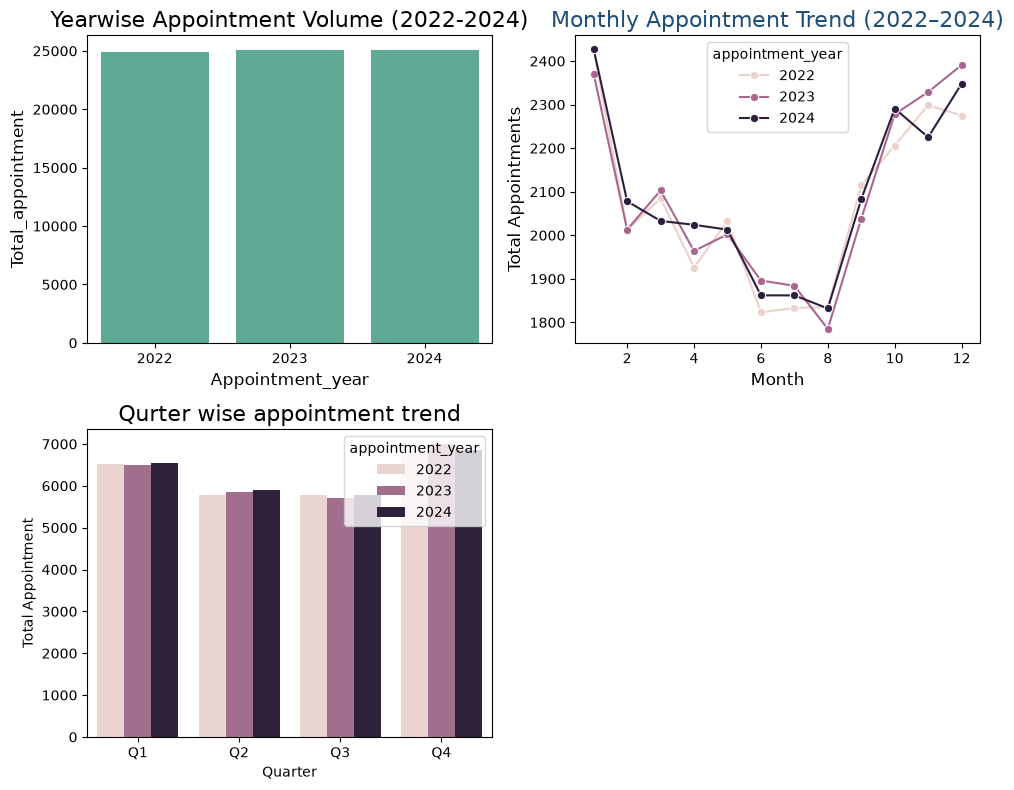

In [127]:
plt.figure(figsize=(10,8))
ax1=plt.subplot(2,2,1)
sns.barplot(data=yearly_appointment, x="appointment_year", y="total_appointment", color="#52B69A",ax=ax1)
ax1.set_title("Yearwise Appointment Volume (2022-2024)", fontsize=16)
ax1.set_xlabel("Appointment_year", fontsize=12)
ax1.set_ylabel("Total_appointment", fontsize=12)


ax2=plt.subplot(2,2,2)
sns.lineplot(
    data=monthly_appointment,
    x="appointment_month",
    y="total_appointment",
    hue="appointment_year",
    marker='o')
ax2.set_title("Monthly Appointment Trend (2022–2024)", fontsize=16, color="#1F4E78")
ax2.set_xlabel("Month", fontsize=12)
ax2.set_ylabel("Total Appointments", fontsize=12)


ax3=plt.subplot(2,2,3)
sns.barplot(data=quarterly_appointment, x="appointment_quarter", y="total_appointment", hue="appointment_year")
ax3.set_title("Qurter wise appointment trend", fontsize=16)
ax3.set_xlabel("Quarter")
ax3.set_ylabel("Total Appointment")


plt.tight_layout()
plt.show()

## Business Insights
Appointment volume increased slightly from 24,868 in 2022 to 25,078 in 2024, showing a stable demand for hospital services.
The fourth quarter recorded higher appointment volumes than the other quarters across all three years.
Appointment volumes were comparatively lower during the second and third quarters.
Management can use these trends to plan doctor availability, staffing and resources according to seasonal demand.

In [93]:
#2.What is the split of outcomes across Completed, No-Show, Cancelled and Scheduled appointments?

#status by appointment count 
status_count = apollo_df["appointment_status"].value_counts().reset_index(name="total_appointment")
status_count

,appointment_status,total_appointment
0,Completed,55275
1,No-Show,11584
2,Cancelled,5793
3,Scheduled,2348


In [112]:
#percetage distribution
status_count["percentage"]=(status_count["total_appointment"]/status_count["total_appointment"].sum())*100
status_count

,appointment_status,total_appointment,percentage
0,Completed,55275,73.700000
1,No-Show,11584,15.445333
2,Cancelled,5793,7.724000
3,Scheduled,2348,3.130667


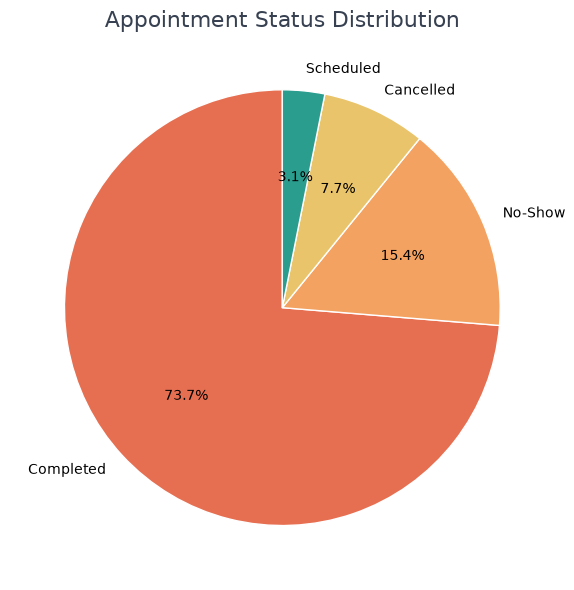

In [96]:
plt.figure(figsize=(8, 6))

plt.pie(
    status_count["total_appointment"],
    labels=status_count["appointment_status"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E76F51", "#F4A261", "#E9C46A", "#2A9D8F"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Appointment Status Distribution", fontsize=16, color="#374151")
plt.tight_layout()
plt.show()

## Business insights
Around 73.7% of appointments were successfully completed, showing that most scheduled visits resulted in consultations.
Approximately 15.45% of appointments were marked as no-shows, indicating a significant attendance challenge.
Cancelled appointments accounted for around 7.72% of the total, while scheduled appointments made up around 3.13%.
Reducing missed appointments and improving rescheduling practices could help hospitals use their available appointment slots more effectively.

In [117]:
#3.Which booking channels drive the highest volume, and how does the channel mix look?

channel_analysis = apollo_df.groupby("booking_channel").size().reset_index(name="total_appointment")
channel_analysis

,booking_channel,total_appointment
0,Apollo App,34042
1,Call Centre,11201
2,Partner App,3711
3,Walk-In,7501
4,Website,18545


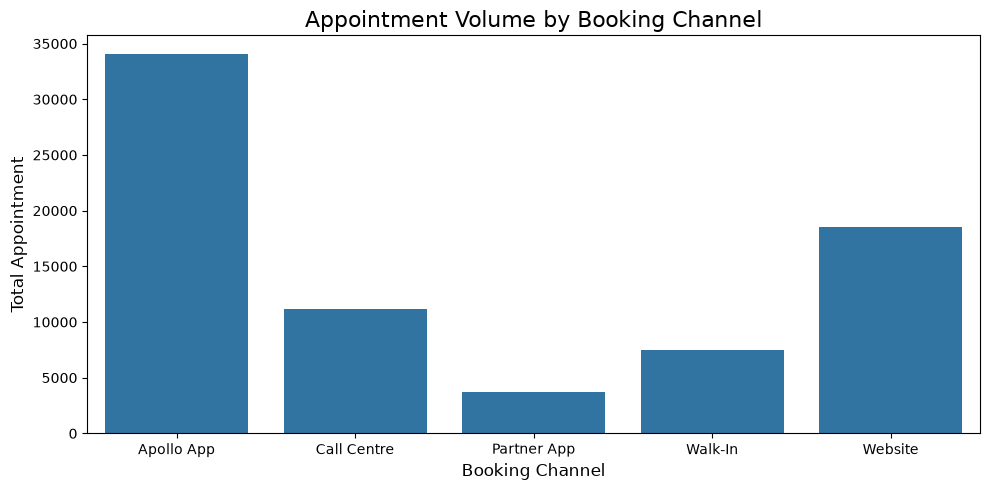

In [122]:
plt.figure(figsize=(10,5))
sns.barplot(data=channel_analysis, x="booking_channel", y="total_appointment",orient="v")
plt.title("Appointment Volume by Booking Channel", fontsize=16)
plt.xlabel("Booking Channel", fontsize=12)
plt.ylabel("Total Appointment", fontsize=12)
plt.tight_layout()
plt.show()

## Business Insights
Appointment bookings increased slightly from 24,868 in 2022 to 25,078 in 2024.
Around 73.7% of appointments were completed, while 15.45% were missed.
The Apollo App was the most preferred booking channel, with 34,042 appointments.

### NO-SHOW Analysis 

In [20]:
valid_df = apollo_df[apollo_df["appointment_status"] != "Scheduled"].copy()
valid_df.columns = valid_df.columns.str.strip()

In [27]:
valid_df["is_no_show"] = np.where(valid_df["appointment_status"]=="No-Show",1,0)


In [152]:
#1. Which medical specialties have the highest and lowest no-show rates?
Speciality_analysis = valid_df.groupby("specialty_x").agg(total_appointment=("appointment_status", "count"),
                                                        total_no_show=("is_no_show", "sum")).reset_index()

Speciality_analysis["no_show_rate"]=( Speciality_analysis["total_no_show"]/Speciality_analysis["total_appointment"])*100

Speciality_analysis

,specialty_x,total_appointment,total_no_show,no_show_rate
0,Cardiology,4484,629,14.027654
1,Dermatology,7566,1608,21.252974
2,ENT,5211,988,18.959893
3,Endocrinology,2024,355,17.539526
4,Gastroenterology,2527,377,14.918876
5,General Physician,19654,3049,15.513381
6,Gynaecology,3991,569,14.257078
7,Neurology,4817,515,10.691302
8,Ophthalmology,3103,503,16.210119
9,Orthopaedics,5419,810,14.947407


In [158]:
Speciality_analysis.sort_values(by="no_show_rate", ascending=False)

,specialty_x,total_appointment,total_no_show,no_show_rate
11,Psychiatry,2900,711,24.517241
1,Dermatology,7566,1608,21.252974
2,ENT,5211,988,18.959893
3,Endocrinology,2024,355,17.539526
8,Ophthalmology,3103,503,16.210119
5,General Physician,19654,3049,15.513381
12,Pulmonology,2549,394,15.457042
9,Orthopaedics,5419,810,14.947407
4,Gastroenterology,2527,377,14.918876
13,Urology,2222,320,14.401440


In [156]:
#city wise no_show rate 
city_analysis = valid_df.groupby("city_x").agg( total_appointment=("appointment_status","count"),total_no_show=("is_no_show","sum")).reset_index()

city_analysis["no_show_rate"]= (city_analysis["total_no_show"]/city_analysis["total_appointment"])*100

city_analysis

,city_x,total_appointment,total_no_show,no_show_rate
0,Ahmedabad,3468,561,16.176471
1,Bengaluru,8343,1287,15.426106
2,Bhopal,2001,336,16.791604
3,Chandigarh,2406,363,15.087282
4,Chennai,6702,1005,14.995524
5,Coimbatore,2162,306,14.153562
6,Delhi,10404,1754,16.858900
7,Hyderabad,7229,1160,16.046479
8,Indore,2149,304,14.146114
9,Jaipur,2653,429,16.170373


In [157]:
city_analysis.sort_values(
    by='no_show_rate',
    ascending=False
)

,city_x,total_appointment,total_no_show,no_show_rate
12,Lucknow,3001,516,17.194269
13,Mumbai,9734,1659,17.043353
6,Delhi,10404,1754,16.858900
2,Bhopal,2001,336,16.791604
11,Kolkata,5701,933,16.365550
10,Kochi,2690,438,16.282528
0,Ahmedabad,3468,561,16.176471
9,Jaipur,2653,429,16.170373
7,Hyderabad,7229,1160,16.046479
1,Bengaluru,8343,1287,15.426106


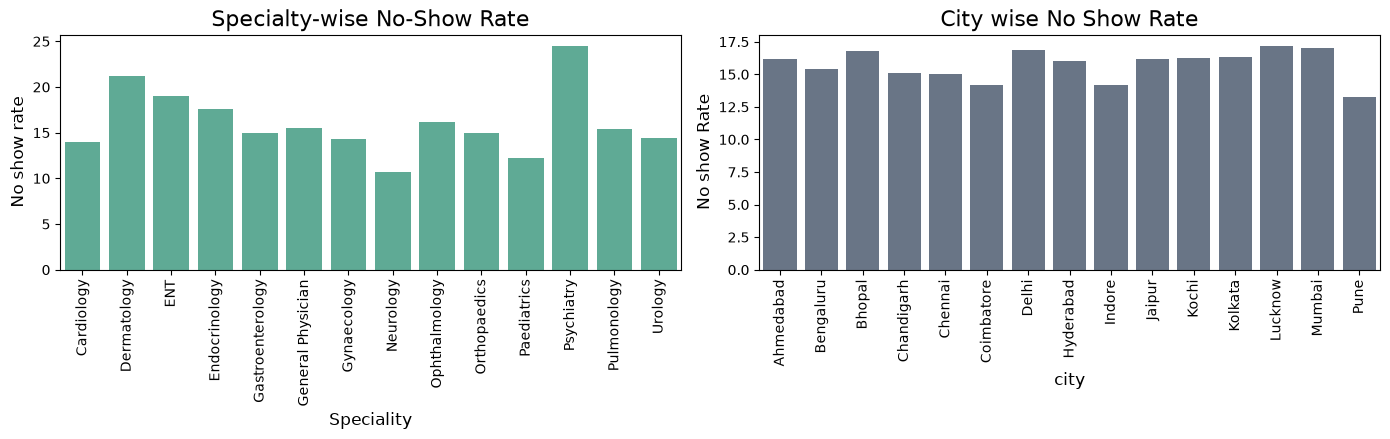

In [174]:
plt.figure(figsize=(14,7))

ax1=plt.subplot(2,2,1)
sns.barplot(data=Speciality_analysis, x="specialty_x", y="no_show_rate",color="#52B69A")
ax1.set_title("Specialty-wise No-Show Rate", fontsize=16)
ax1.set_xlabel("Speciality", fontsize=12)
ax1.set_ylabel("No show rate", fontsize=12)
plt.xticks(rotation=90)

ax2=plt.subplot(2,2,2)
sns.barplot(data=city_analysis, x="city_x",y="no_show_rate",color="#64748B")
ax2.set_title("City wise No Show Rate", fontsize=16)
ax2.set_xlabel("city", fontsize=12)
ax2.set_ylabel("No show Rate",fontsize=12)
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### Business Insights
Psychiatry recorded the highest no-show rate at approximately 24.52%, followed by Dermatology at 21.25%.
Neurology had the lowest no-show rate at approximately 10.69%, indicating better appointment attendance in this specialty.
Higher no-show rates in certain specialties may result in unused consultation slots and lost revenue opportunities.
Apollo can consider additional reminders and follow-up communication for specialties where missed appointments are more common.

In [25]:
#2.How does booking lead time affect the probability of a No-Show?

valid_df["lead_time_group"]=pd.cut(valid_df["booking_lead_days"],
                                   bins=[-1, 1, 7, 14, 30, float('inf')],
                                   labels=["0-1 Days", "2-7 Days", "8-14 Days", "15-30 Days", "Above 30 Days"])


In [32]:
lead_time_analysis = valid_df.groupby("lead_time_group").agg(total_appointment=("appointment_status","count"),
                                                             total_no_show=("is_no_show","sum")).reset_index()

lead_time_analysis["no_show_rate"]= (lead_time_analysis["total_no_show"]/lead_time_analysis["total_appointment"])*100

lead_time_analysis

,lead_time_group,total_appointment,total_no_show,no_show_rate
0,0-1 Days,30633,4575,14.934874
1,2-7 Days,30919,4892,15.821986
2,8-14 Days,8758,1648,18.817082
3,15-30 Days,2342,469,20.025619


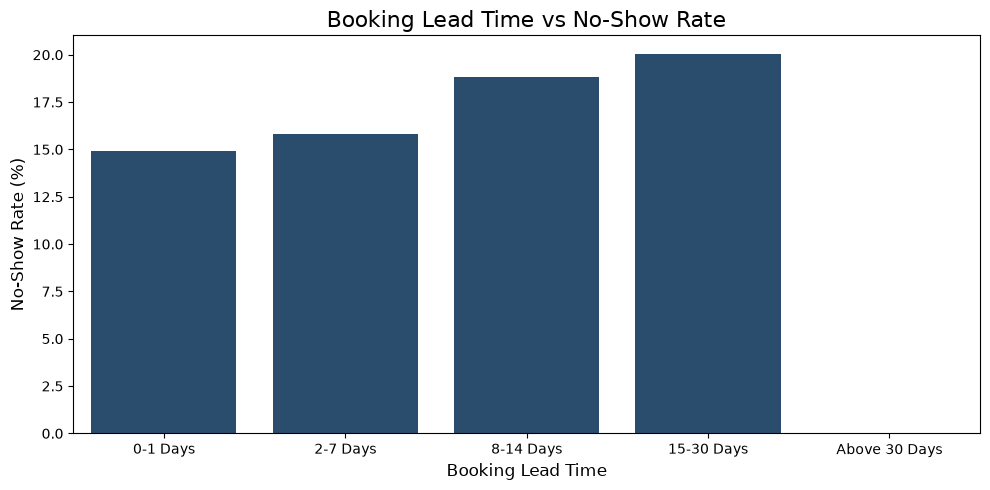

In [36]:
plt.figure(figsize=(10, 5))

sns.barplot(data=lead_time_analysis,x='lead_time_group',y='no_show_rate',color='#1F4E78')
plt.title('Booking Lead Time vs No-Show Rate', fontsize=16)
plt.xlabel('Booking Lead Time',fontsize=12)
plt.ylabel('No-Show Rate (%)',fontsize=12)

plt.tight_layout()
plt.show()

### Business Insights
Appointments booked 15–30 days in advance had the highest observed no-show rate, at approximately 20.03%.
Appointments booked within 0–1 days had a lower no-show rate of approximately 14.93%.
The no-show rate generally increased as the gap between booking and appointment dates became longer.
Sending reminders at suitable intervals may help patients remember appointments booked well in advance.

In [42]:
#3.Do evening slots, weekends, and longer-lead bookings see higher dropout? 

#timeslot for appointmet
valid_df["Time_slot"] = pd.cut(valid_df["appointment_hour"], bins=[-1, 11, 16, 23], labels=['Morning', 'Afternoon', 'Evening'])

time_analysis = valid_df.groupby("time_slot").agg(total_appointment=("appointment_status", "count"),
                                                  total_no_show=("is_no_show", "sum")).reset_index()

time_analysis["no_show_rate"] = (time_analysis["total_no_show"]/ time_analysis["total_appointment"]) * 100

In [43]:
#weekned slot for appointment
valid_df["day_type"] = np.where(valid_df["appointment_day"].isin(['Saturday', 'Sunday']), "Weekend", "Weekday")

day_analysis = valid_df.groupby("day_type").agg(total_appointment=("appointment_status", "count"),total_no_show=("is_no_show", "sum")).reset_index()

day_analysis["no_show_rate"] = (day_analysis["total_no_show"]/ day_analysis["total_appointment"]) * 100

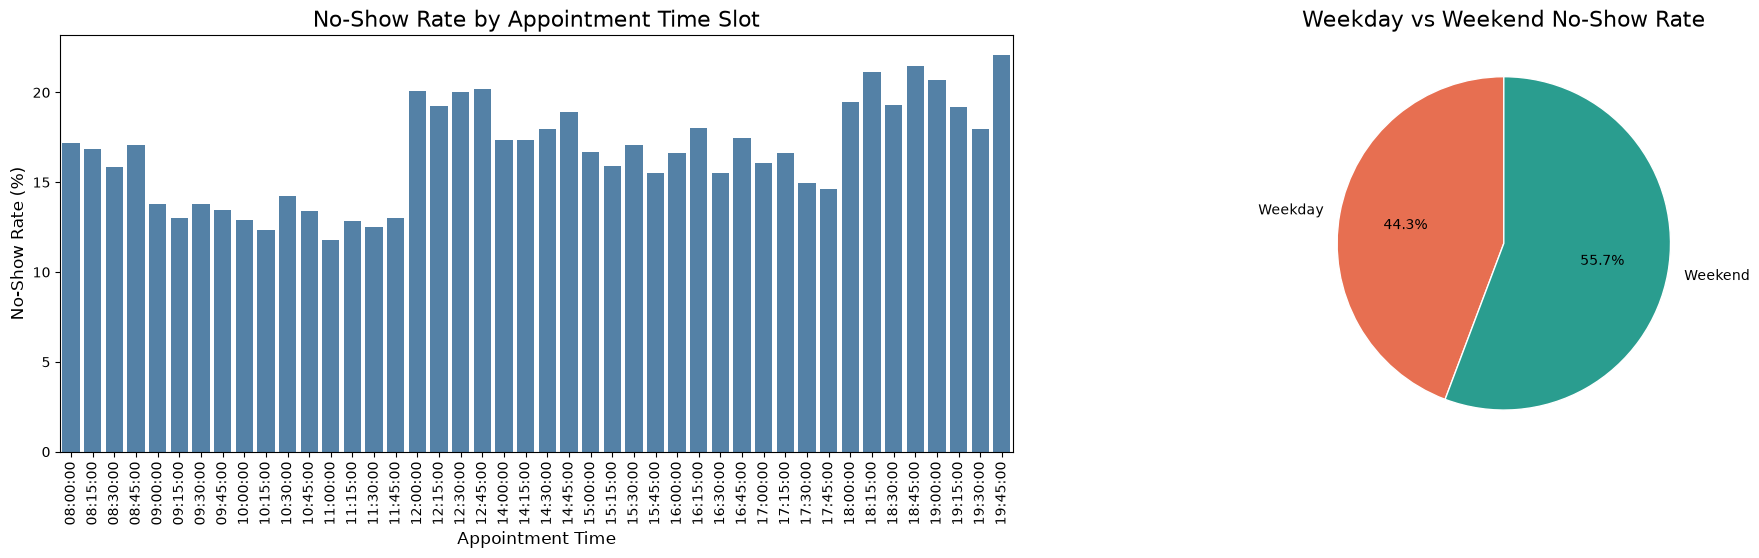

In [98]:
plt.figure(figsize=(20,10))
ax1=plt.subplot(2,2,1)
sns.barplot(
    data=time_analysis,
    x="time_slot",
    y="no_show_rate",
    color="steelblue")
ax1.set_title("No-Show Rate by Appointment Time Slot", fontsize=16)
ax1.set_xlabel("Appointment Time",fontsize=12)
ax1.set_ylabel("No-Show Rate (%)",fontsize=12)
plt.xticks(rotation=90)


ax2 = plt.subplot(2, 2, 2)
plt.pie(
    day_analysis["no_show_rate"],
    labels=day_analysis["day_type"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E76F51", "#2A9D8F"],
    wedgeprops={"edgecolor": "white"})
plt.title("Weekday vs Weekend No-Show Rate", fontsize=16)

plt.tight_layout()
plt.show()

### Business Insights
Comparing appointment time slots helps identify whether attendance patterns differ between morning, afternoon and evening.
Comparing weekday and weekend appointments helps management understand whether appointment timing is linked to missed visits.
These patterns can help identify time slots that may need additional patient communication.
Apollo can use the findings to improve appointment scheduling and reminder timing.

In [56]:
#4.Which appointment types and booking channels carry the most no-show risk?

# Appointment type no show analysis
type_analysis = valid_df.groupby("appointment_type").agg( total_appointment=("appointment_status", "count"),
                                                          total_no_show=("is_no_show", "sum")).reset_index()

type_analysis["no_show_rate"] = ( type_analysis["total_no_show"]/ type_analysis["total_appointment"]) * 100



In [57]:
#booking Channel no show risk
channel_analysis = valid_df.groupby("booking_channel").agg(total_appointment=("appointment_status", "count"),
                                                           total_no_show=("is_no_show", "sum")).reset_index()

channel_analysis["no_show_rate"] = (channel_analysis["total_no_show"]/ channel_analysis["total_appointment"]) * 100

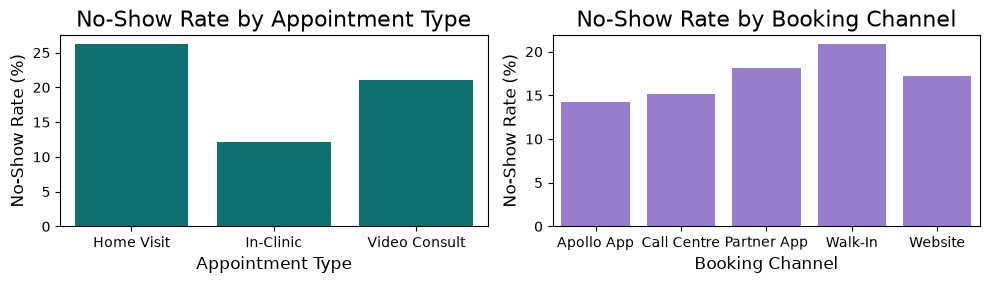

In [63]:
plt.figure(figsize=(10, 5))

ax1=plt.subplot(2,2,1)
sns.barplot(
    data=type_analysis,
    x="appointment_type",
    y="no_show_rate",
    color="teal")
ax1.set_title("No-Show Rate by Appointment Type",fontsize=16)
ax1.set_xlabel("Appointment Type",fontsize=12)
ax1.set_ylabel("No-Show Rate (%)",fontsize=12)
plt.xticks(rotation=0)


ax2=plt.subplot(2,2,2)
sns.barplot(
    data=channel_analysis,
    x="booking_channel",
    y="no_show_rate",
    color="mediumpurple")
ax2.set_title("No-Show Rate by Booking Channel",fontsize=16)
ax2.set_xlabel("Booking Channel",fontsize=12)
ax2.set_ylabel("No-Show Rate (%)",fontsize=12)
plt.xticks(rotation=0)


plt.tight_layout()
plt.show()

### Business Insights

Comparing appointment time slots helps identify whether attendance patterns differ between morning, afternoon and evening.
Comparing weekday and weekend appointments helps management understand whether appointment timing is linked to missed visits.
These patterns can help identify time slots that may need additional patient communication.
Apollo can use the findings to improve appointment scheduling and reminder timing.

### Reminder and Engagement Effectiveness 

In [69]:

#1.How much does reminder type reduce no-show rates compared to no-reminder patients?
reminder_analysis = valid_df.groupby("reminder_type").agg(total_appointments=("appointment_status", "count"),
                                                          total_no_shows=("is_no_show", "sum")).reset_index()

reminder_analysis["no_show_rate"] = (reminder_analysis["total_no_shows"]/ reminder_analysis["total_appointments"]) * 100

reminder_analysis

,reminder_type,total_appointments,total_no_shows,no_show_rate
0,No Reminder,10977,3311,30.163068
1,SMS + WhatsApp,25273,3414,13.508487
2,SMS + WhatsApp + Call,21875,2496,11.410286
3,SMS Only,14527,2363,16.266263


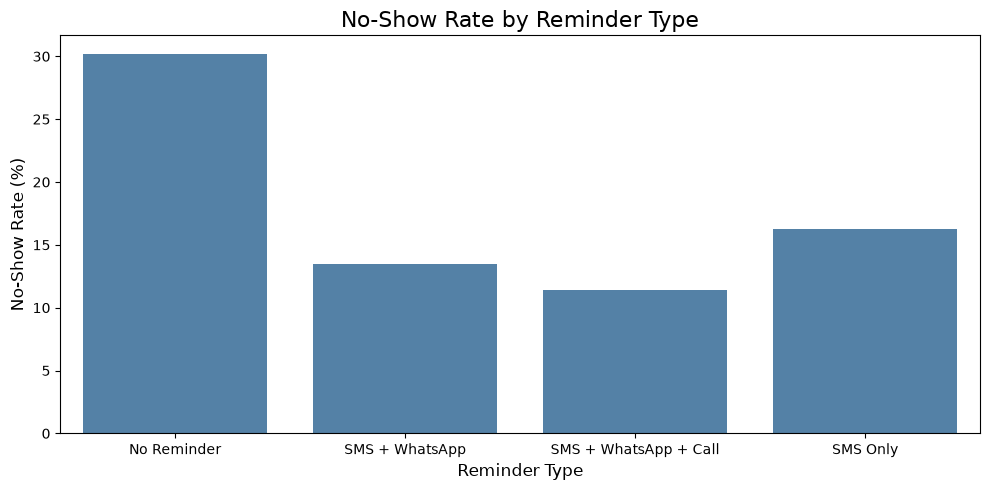

In [71]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=reminder_analysis,
    x="reminder_type",
    y="no_show_rate",
    color="steelblue")
plt.title("No-Show Rate by Reminder Type",fontsize=16)
plt.xlabel("Reminder Type",fontsize=12)
plt.ylabel("No-Show Rate (%)",fontsize=12)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Business Insights

Patients who received no reminders had a no-show rate of approximately 30.16%, the highest among the reminder groups.
The SMS, WhatsApp and call combination recorded the lowest no-show rate at approximately 11.41%.
Patients receiving SMS and WhatsApp reminders had a no-show rate of approximately 13.51%, compared with 16.27% for SMS-only reminders.
The results suggest that regular patient communication may help improve attendance. Apollo can evaluate combined reminders as part of its appointment management strategy.

In [77]:
#Does prior no-show history predict future no-show behaviour? 

history_analysis = valid_df.groupby("patient_prior_no_shows").agg(total_appointments=("appointment_status", "count"),
                                                             total_no_shows=("is_no_show", "sum")).reset_index()

history_analysis["no_show_rate"] = (history_analysis["total_no_shows"]/ history_analysis["total_appointments"]) * 100


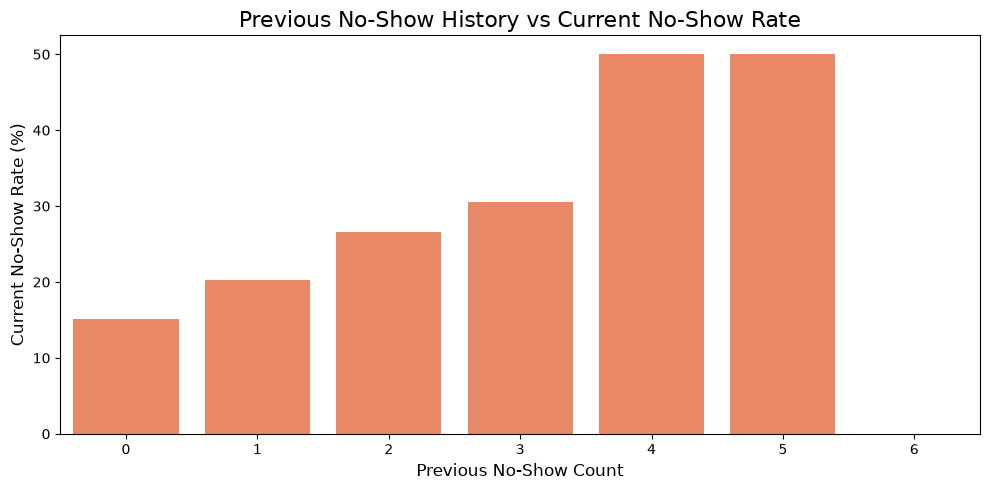

In [90]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=history_analysis,
    x="patient_prior_no_shows",
    y="no_show_rate",
    color="coral")
plt.title("Previous No-Show History vs Current No-Show Rate",fontsize=16)
plt.xlabel("Previous No-Show Count",fontsize=12)
plt.ylabel("Current No-Show Rate (%)",fontsize=12)

plt.tight_layout()
plt.show()

### Business Insights
Analysing previous no-show records helps identify patients who may need additional appointment support.
Patients with a history of missed appointments can be considered for more personalised reminders.
This analysis can help Apollo identify potential attendance risks before the appointment date.
A patient follow-up strategy may help reduce repeated missed appointments and improve appointment utilisation.

In [104]:
#3.Do Apollo members and repeat patients show better attendance than non-members and first-time patients? 

#people with membership card
membership_analysis = valid_df.groupby("membership_type").agg(total_appointments=("appointment_status", "count"),
    completed_appointments=("appointment_status", lambda x: (x == "Completed").sum())).reset_index()

valid_df["is_completed"] = np.where( valid_df["appointment_status"] == "Completed", 1,0)

membership_analysis = valid_df.groupby("membership_type").agg(total_appointments=("appointment_status", "count"),
                                                              completed_appointments=("is_completed", "sum")).reset_index()

membership_analysis["attendance_rate"] = (membership_analysis["completed_appointments"]/ membership_analysis["total_appointments"]) * 100

membership_analysis


,membership_type,total_appointments,completed_appointments,attendance_rate
0,Apollo Gold,8167,6456,79.049835
1,Apollo Silver,8057,6417,79.645029


In [112]:
#people without membership card
patient_analysis = valid_df.groupby("apollo_member").agg(total_appointments=("appointment_status", "count"),
                                                         completed_appointments=("is_completed", "sum")).reset_index()

patient_analysis["attendance_rate"] = ( patient_analysis["completed_appointments"]/ patient_analysis["total_appointments"]) * 100



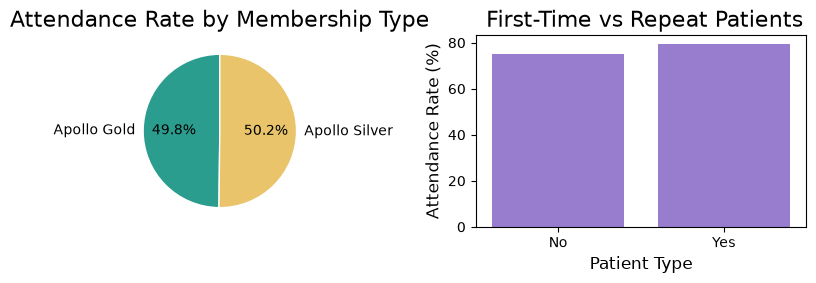

In [118]:
plt.figure(figsize=(8, 5))
ax1=plt.subplot(2,2,1)
plt.pie(membership_analysis["attendance_rate"],
    labels=membership_analysis["membership_type"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#2A9D8F", "#E9C46A", "#E76F51"],
    wedgeprops={"edgecolor": "white"})

ax1.set_title("Attendance Rate by Membership Type", fontsize=16)


ax2=plt.subplot(2,2,2)
sns.barplot(
    data=patient_analysis,
    x="apollo_member",
    y="attendance_rate",
    color="mediumpurple")
ax2.set_title(" First-Time vs Repeat Patients",fontsize=16)
ax2.set_xlabel("Patient Type",fontsize=12)
ax2.set_ylabel("Attendance Rate (%)",fontsize=12)


plt.tight_layout()
plt.show()

### Business Insights
Apollo Gold members recorded an attendance rate of approximately 79.05%, while Apollo Silver members recorded approximately 79.65%.
The attendance rates of Gold and Silver members were very similar, with Silver members showing a slightly higher rate.
Comparing members with non-members and repeat patients with first-time patients helps Apollo understand whether patient relationships are associated with attendance.
These findings can support better patient engagement and retention strategies.

# Patient and Demographic Segmentation 

In [121]:
#1.How do age group, gender, and chronic condition status influence no-show likelihood?

#Age Group vs No-Show Rate
valid_df["age_group"] = pd.cut(
    valid_df["patient_age"],
    bins=[0, 18, 30, 45, 60, float("inf")],
    labels=["0-18","19-30","31-45","46-60","Above 60"],
    include_lowest=True)

age_analysis = valid_df.groupby("age_group", observed=False).agg(total_appointments=("appointment_status", "count"),
                                                                 total_no_shows=("is_no_show", "sum")).reset_index()

age_analysis["no_show_rate"] = (age_analysis["total_no_shows"] / age_analysis["total_appointments"]) * 100



In [125]:
#Gender vs No-Show Rate
 
gender_analysis = valid_df.groupby("patient_gender").agg(total_appointments=("appointment_status", "count"),
                                                 total_no_shows=("is_no_show", "sum")).reset_index()

gender_analysis["no_show_rate"] = (gender_analysis["total_no_shows"]/ gender_analysis["total_appointments"]) * 100



In [129]:
#Chronic Condition Status vs No-Show Rate
chronic_analysis = valid_df.groupby("patient_chronic_condition").agg(total_appointments=("appointment_status", "count"),
                                                              total_no_shows=("is_no_show", "sum")).reset_index()

chronic_analysis["no_show_rate"] = (chronic_analysis["total_no_shows"]/ chronic_analysis["total_appointments"]) * 100


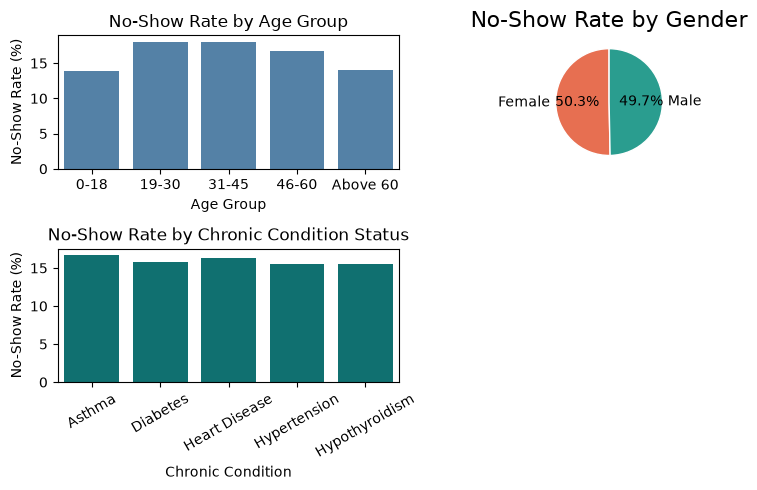

In [134]:
plt.figure(figsize=(8, 5))

ax1 = plt.subplot(2,2,1)
sns.barplot(
    data=age_analysis,
    x="age_group",
    y="no_show_rate",
    color="steelblue")
ax1.set_title("No-Show Rate by Age Group")
ax1.set_xlabel("Age Group")
ax1.set_ylabel("No-Show Rate (%)")


ax2 = plt.subplot(2, 2, 2)
plt.pie(gender_analysis["no_show_rate"],
    labels=gender_analysis["patient_gender"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E76F51", "#2A9D8F"],
    wedgeprops={"edgecolor": "white"})
ax2.set_title("No-Show Rate by Gender", fontsize=16)


ax3=plt.subplot(2,2,3)
sns.barplot(
    data=chronic_analysis,
    x="patient_chronic_condition",
    y="no_show_rate",
    color="teal")
ax3.set_title("No-Show Rate by Chronic Condition Status")
ax3.set_xlabel("Chronic Condition")
ax3.set_ylabel("No-Show Rate (%)")
plt.xticks(rotation=30)


plt.tight_layout()
plt.show()

### Business Insights
Comparing no-show rates across age groups helps identify whether appointment attendance differs between younger and older patients.
Gender-based analysis provides another view of patient attendance patterns and may help identify differences in appointment behaviour.
Analysing chronic condition status helps Apollo understand whether attendance patterns vary between patients with and without recorded chronic conditions.
These findings can support more targeted patient communication, but demographic factors should not be treated as the direct cause of missed appointments.

In [137]:
#2.Which visit reasons are most common and are some associated with higher dropout? 
visit_reason_count = valid_df["visit_reason"].value_counts()


In [143]:
#No-Show Rate by Visit Reason
visit_analysis = valid_df.groupby("visit_reason").agg(total_appointments=("appointment_status", "count"),
                                                      total_no_shows=("is_no_show", "sum")).reset_index()

visit_analysis["no_show_rate"] = (visit_analysis["total_no_shows"]/ visit_analysis["total_appointments"]) * 100

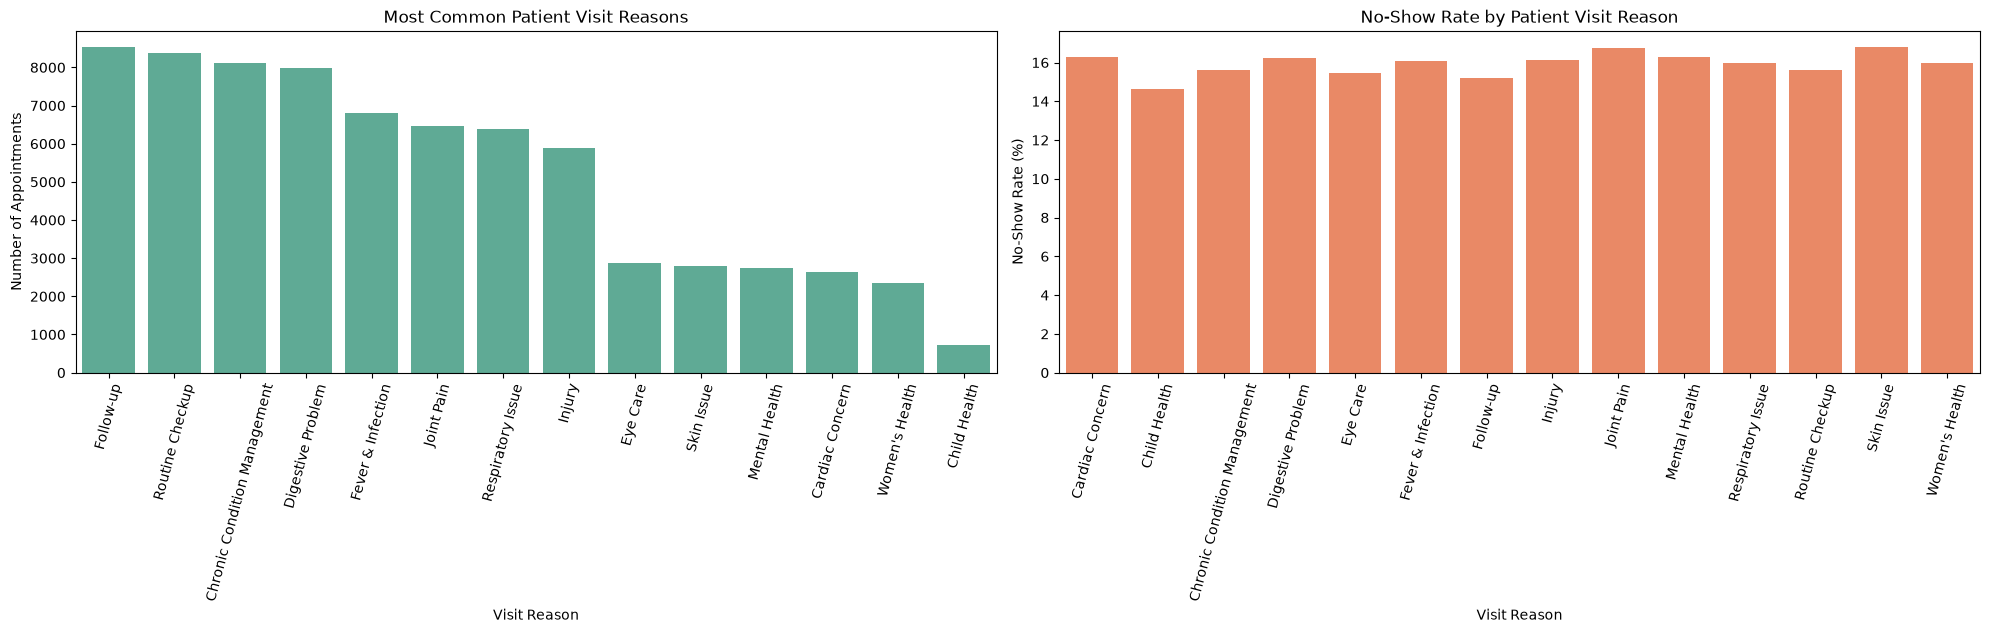

In [149]:
plt.figure(figsize=(20, 10))
ax1=plt.subplot(2,2,1)
sns.countplot(
    data=valid_df,
    x="visit_reason",
    color="#52B69A",
    order=visit_reason_count.index)
ax1.set_title("Most Common Patient Visit Reasons")
ax1.set_xlabel("Visit Reason")
ax1.set_ylabel("Number of Appointments")
plt.xticks(rotation=75)


ax2=plt.subplot(2,2,2)
sns.barplot(
    data=visit_analysis,
    x="visit_reason",
    y="no_show_rate",
    color="coral")
ax2.set_title("No-Show Rate by Patient Visit Reason")
ax2.set_xlabel("Visit Reason")
ax2.set_ylabel("No-Show Rate (%)")
plt.xticks(rotation=75)


plt.tight_layout()
plt.show()

### Business Insights
Analysing visit reasons helps Apollo understand the most common reasons patients seek medical consultations.
Comparing appointment volumes with no-show rates helps distinguish frequently requested services from services with higher attendance risks.
Visit reasons associated with higher no-show rates may need better appointment confirmation and follow-up.
This analysis can help hospitals improve patient communication and appointment planning across different healthcare needs.

In [157]:
#3.What does patient age distribution look like within Paediatrics, Gynaecology and Psychiatry?
specialty_age = apollo_df[ apollo_df["specialty_x"].isin( ["Paediatrics", "Gynaecology", "Psychiatry"])]

age_specialty_analysis = specialty_age.groupby( "specialty_x")["patient_age"].mean().reset_index()

age_specialty_analysis


,specialty_x,patient_age
0,Gynaecology,41.689764
1,Paediatrics,9.251959
2,Psychiatry,41.964537


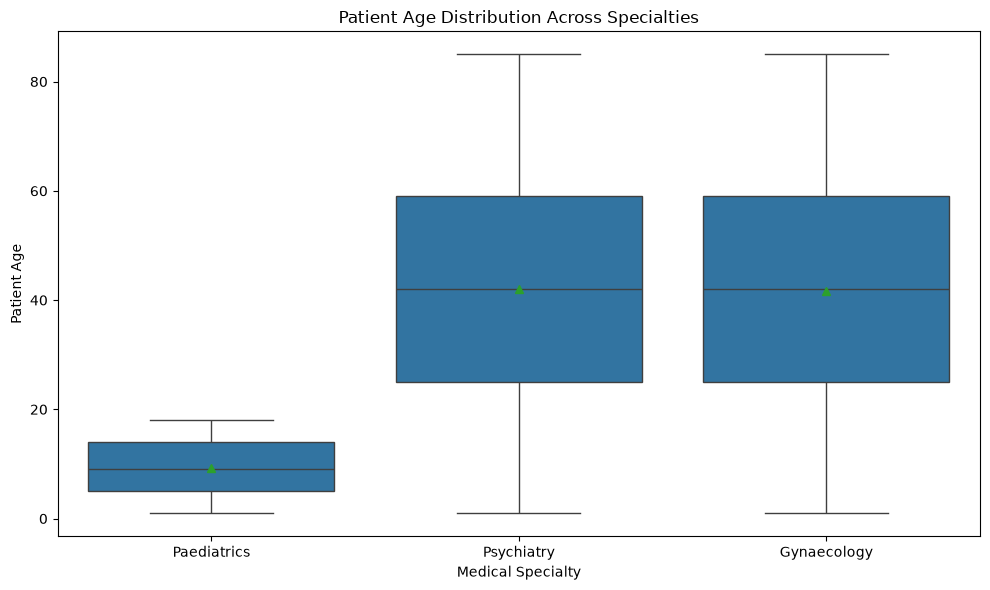

In [162]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=specialty_age,
    x="specialty_x",
    y="patient_age",
    showmeans=True
)

plt.title("Patient Age Distribution Across Specialties")
plt.xlabel("Medical Specialty")
plt.ylabel("Patient Age")

plt.tight_layout()
plt.show()

### Business Insights
Paediatrics had the lowest average patient age, at approximately 9.25 years, which is consistent with its focus on child healthcare.
Gynaecology recorded an average patient age of approximately 41.69 years.
Psychiatry recorded an average patient age of approximately 41.96 years.
Understanding age distribution across specialties can help Apollo plan suitable services, patient communication and healthcare resources.

### Financial Performance 

In [169]:
#.How much total revenue was generated by Apollo Hospitals?
completed_df = apollo_df[ apollo_df["appointment_status"] == "Completed"].copy()

completed_df["revenue_realized"] = pd.to_numeric(completed_df["revenue_realized"],errors="coerce")

total_revenue = completed_df["revenue_realized"].sum()
print("Total Revenue:", total_revenue)


Total Revenue: 73893798


In [171]:
average_revenue = completed_df["revenue_realized"].mean()

print("Average Revenue per Completed Appointment:", average_revenue)

Average Revenue per Completed Appointment: 1336.8394029850747


#### Business Insights ### 

1. Apollo Hospitals generated total revenue of ₹ 73893798 from completed appointments.
2. The average revenue per completed appointment was ₹1336.84 .
3. Total revenue provides an overview of the hospital's financial performance.
4. Average revenue per appointment helps management understand the revenue contribution of individual appointments.
5. Management can use these metrics to monitor revenue performance and identify opportunities to improve financial outcomes.

In [176]:
#1.How much revenue is being lost to no-shows? 
no_show_df = apollo_df[apollo_df["appointment_status"] == "No-Show"].copy()

total_no_show = no_show_df.shape[0]
print("Total No-Show Appointments:", total_no_show)

potential_revenue_loss = no_show_df["consultation_fee_y"].sum()
print("Potential Revenue Loss:", potential_revenue_loss)

average_loss = no_show_df["consultation_fee_y"].mean()
print("Average Potential Loss per No-Show:", average_loss)

Total No-Show Appointments: 11584
Potential Revenue Loss: 18363700
Average Potential Loss per No-Show: 1585.2641574585634


### Business Insights
A total of 11,584 appointments were marked as no-shows, representing missed consultation opportunities.
The estimated potential revenue associated with these appointments was approximately ₹1.84 crore, based on consultation fees.
The average potential revenue per missed appointment was approximately ₹1,585.
Reducing no-shows through reminders and rescheduling options could help Apollo recover some of these potential revenue opportunities.

In [189]:
#2.How does average revenue vary across specialties and appointment types? 

#average revenue by specialty
specialty_revenue = completed_df.groupby("specialty_x").agg(
    average_revenue=("revenue_realized", "mean"),
    total_revenue=("revenue_realized", "sum"),
    total_appointments=("revenue_realized", "count")).reset_index()

specialty_revenue = specialty_revenue.sort_values(by="average_revenue",ascending=True)


In [190]:
#average revenue by appointment type
appointment_type_revenue = completed_df.groupby("appointment_type").agg(
    average_revenue=("revenue_realized", "mean"),
    total_revenue=("revenue_realized", "sum"),
    total_appointments=("revenue_realized", "count")).reset_index()

appointment_type_revenue = appointment_type_revenue.sort_values(by="average_revenue",ascending=False)
appointment_type_revenue

,appointment_type,average_revenue,total_revenue,total_appointments
0,Home Visit,1960.048322,12614871,6436
1,In-Clinic,1299.829959,49312949,37938
2,Video Consult,1097.695441,11965978,10901


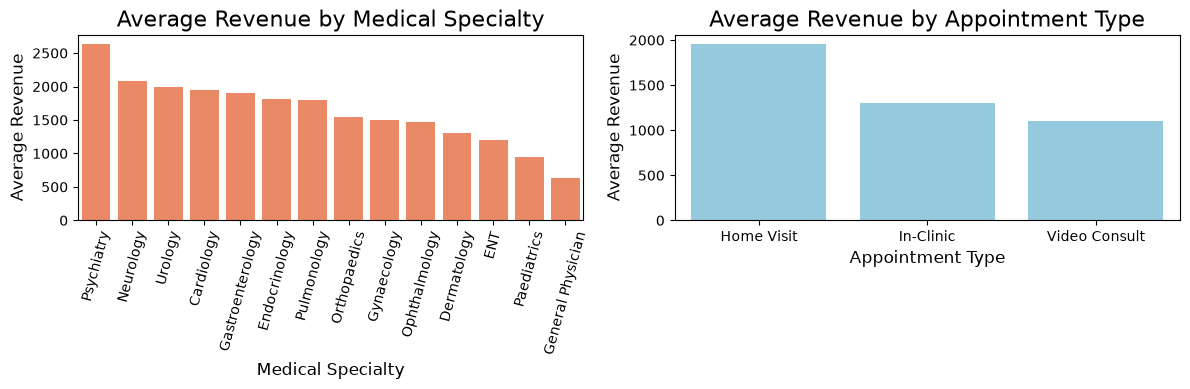

In [186]:
plt.figure(figsize=(12, 6))

ax1=plt.subplot(2,2,1)
sns.barplot(data=specialty_revenue,
           x="specialty_x",
           y="average_revenue",
           color="coral")
ax1.set_title("Average Revenue by Medical Specialty",fontsize=16)
ax1.set_xlabel("Medical Specialty",fontsize=12)
ax1.set_ylabel("Average Revenue",fontsize=12)
plt.xticks(rotation=75)


ax2=plt.subplot(2,2,2)
sns.barplot(data=appointment_type_revenue,
            x="appointment_type",
            y="average_revenue",
            color="skyblue")

ax2.set_title("Average Revenue by Appointment Type",fontsize=16)
ax2.set_xlabel("Appointment Type",fontsize=12)
ax2.set_ylabel("Average Revenue",fontsize=12)
plt.xticks(rotation=0)


plt.tight_layout()
plt.show()

### Key Business Insights
Psychiatry generated the highest average revenue among the medical specialties analysed.
General Physician recorded the lowest average revenue per completed appointment among the specialties.
Home Visits generated the highest average revenue per appointment, at approximately ₹1,960.
Understanding revenue differences across specialties and appointment types can help management evaluate service performance and plan its service offerings.

In [198]:
#3.Which cities generate the most revenue and what is the payment mode mix? 
#Revenue by city
city_revenue = completed_df.groupby("city_x").agg(
    total_revenue=("revenue_realized", "sum"),
    total_appointments=("revenue_realized", "count"),
    average_revenue=("revenue_realized", "mean")).reset_index()

city_revenue = city_revenue.sort_values(by="total_revenue",ascending=True)



In [196]:
#payment mode count and percentage
payment_analysis = completed_df["payment_mode"].value_counts().reset_index()

payment_analysis.columns = ["payment_mode", "total_transactions"]

payment_analysis["percentage"] = (payment_analysis["total_transactions"] /payment_analysis["total_transactions"].sum()) * 100


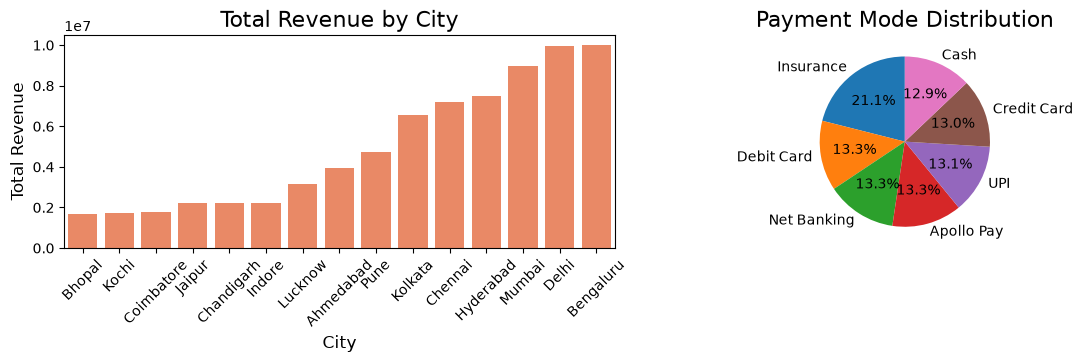

In [203]:
plt.figure(figsize=(12, 6))

ax1=plt.subplot(2,2,1)
sns.barplot(data=city_revenue,
            x="city_x",
            y="total_revenue",
            color="coral")
ax1.set_title("Total Revenue by City",fontsize=16)
ax1.set_xlabel("City",fontsize=12)
ax1.set_ylabel("Total Revenue",fontsize=12)
plt.xticks(rotation=45)


ax2=plt.subplot(2,2,2)
plt.pie(payment_analysis["total_transactions"],
        labels=payment_analysis["payment_mode"],
        autopct="%1.1f%%",
        startangle=90)

ax2.set_title("Payment Mode Distribution", fontsize=16)

plt.tight_layout()
plt.show()

### Key Business Insights
Comparing city-wise revenue helps Apollo understand how much each location contributes to the hospital's overall financial performance.
Revenue differences between cities can help management identify locations that may need further business attention.
Analysing payment modes helps Apollo understand how patients prefer to pay for completed appointments.
These findings can support location-wise performance reviews and improvements in the payment experience.

In [207]:
#4.How does insurance coverage affect what patients pay out of pocket? 
insurance_analysis = completed_df.groupby("insurance_provider").agg(average_out_of_pocket=("patient_out_of_pocket", "mean"),
                                                                    total_out_of_pocket=("patient_out_of_pocket", "sum"),
                                                                    total_appointments=("patient_out_of_pocket", "count")).reset_index()



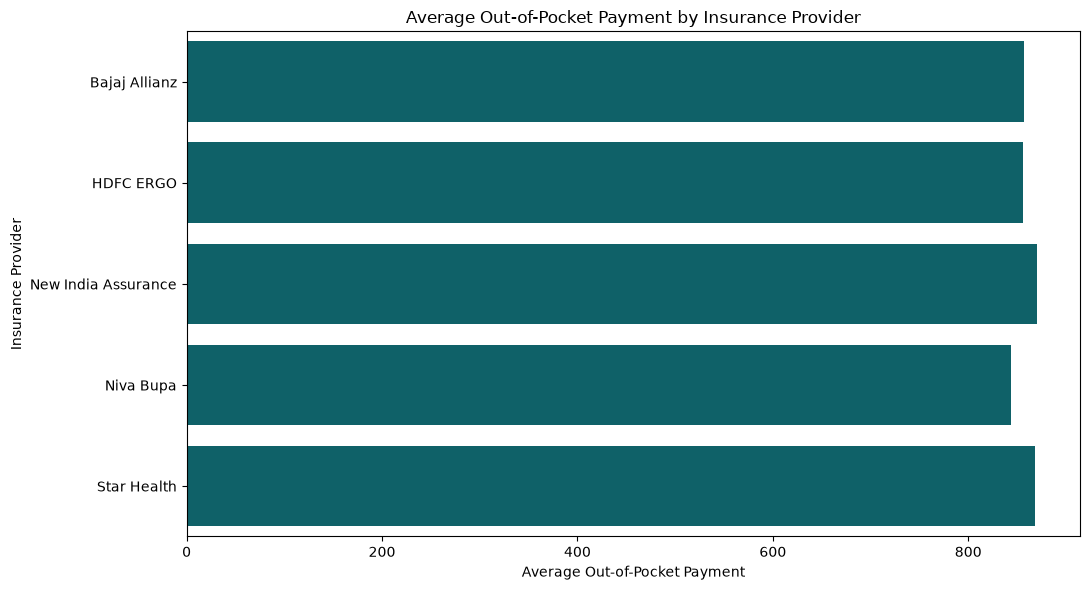

In [212]:
plt.figure(figsize=(11, 6))

sns.barplot( data=insurance_analysis,
    x="average_out_of_pocket",
    y="insurance_provider",
    color="#006D77")
plt.title("Average Out-of-Pocket Payment by Insurance Provider")
plt.xlabel("Average Out-of-Pocket Payment")
plt.ylabel("Insurance Provider")

plt.tight_layout()
plt.show()

### Business Insights
Comparing average out-of-pocket payments across insurance providers helps Apollo understand the amount patients pay themselves.
Differences in patient payments may indicate that insurance coverage and benefits vary across providers.
This analysis can help identify insurance arrangements where patients have higher out-of-pocket expenses.
Understanding these differences can support better insurance coordination and help improve the patient payment experience.

### Doctor Utilisation and Service Quality 

In [222]:
#1.Which specialties have the highest and lowest doctor utilisation rates? 
specialty_utilisation = completed_df.groupby("specialty_x").agg(
    average_utilisation=("doctor_utilization_pct", "mean"),
    total_appointments=("doctor_utilization_pct", "count")).reset_index()

specialty_utilisation = specialty_utilisation.sort_values(by="average_utilisation",ascending=True)
specialty_utilisation


,specialty_x,average_utilisation,total_appointments
11,Psychiatry,76.181052,1958
8,Ophthalmology,76.193401,2349
2,ENT,76.327542,3845
12,Pulmonology,76.354615,1961
1,Dermatology,76.420516,5347
9,Orthopaedics,76.430485,4189
13,Urology,76.442568,1729
5,General Physician,76.590615,14981
7,Neurology,76.632342,3899
10,Paediatrics,76.664143,4900


In [218]:
highest_utilisation = specialty_utilisation.iloc[0]

lowest_utilisation = specialty_utilisation.iloc[-1]

print("Highest Utilisation Specialty:")
print(highest_utilisation)

print("Lowest Utilisation Specialty:")
print(lowest_utilisation)

Highest Utilisation Specialty:
specialty_x            Gastroenterology
average_utilisation           77.256288
total_appointments                 1972
Name: 4, dtype: object
Lowest Utilisation Specialty:
specialty_x            Psychiatry
average_utilisation     76.181052
total_appointments           1958
Name: 11, dtype: object


### Business Insights
Gastroenterology recorded the highest average doctor utilisation at approximately 77.26%.
Psychiatry recorded the lowest average utilisation at approximately 76.18%.
Utilisation rates across specialties were very close, with a difference of only around 1.08 percentage points between the highest and lowest.
Management can monitor utilisation across specialties to plan doctor schedules and make better use of available consultation capacity.

In [227]:
#2.How long are patients waiting and does it vary by specialty or time of day? 

#Average waiting time by specialty
waiting_specialty = completed_df.groupby("specialty_x").agg(
    average_waiting_time=("wait_time_minutes", "mean"),
    total_appointments=("wait_time_minutes", "count")).reset_index()

waiting_specialty = waiting_specialty.sort_values(by="average_waiting_time", ascending=False)


In [232]:
#average waiting time by time slot
completed_df["time_slot"] = pd.cut(completed_df["appointment_hour"],bins=[-1, 11, 16, 23],labels=["Morning", "Afternoon", "Evening"])


waiting_time_slot = completed_df.groupby("time_slot", observed=False).agg(
    average_waiting_time=("wait_time_minutes", "mean"),
    total_appointments=("wait_time_minutes", "count")).reset_index()
waiting_time_slot

,time_slot,average_waiting_time,total_appointments
0,Morning,11.546854,27287
1,Afternoon,11.552577,17270
2,Evening,11.551782,10718


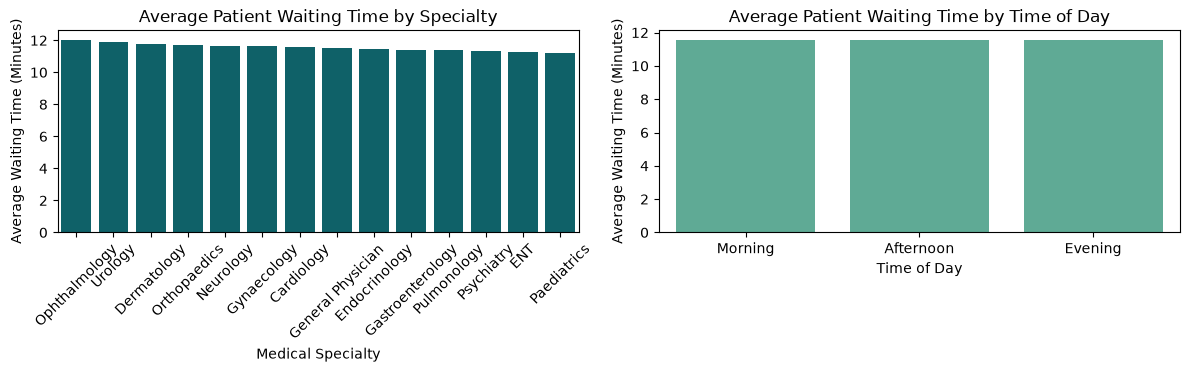

In [231]:
plt.figure(figsize=(12, 6))

ax1=plt.subplot(2,2,1)
sns.barplot(data=waiting_specialty,
    x="specialty_x",
    y="average_waiting_time",
    color="#006D77")
ax1.set_title("Average Patient Waiting Time by Specialty")
ax1.set_xlabel("Medical Specialty")
ax1.set_ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=45)

ax2=plt.subplot(2,2,2)
sns.barplot(
    data=waiting_time_slot,
    x="time_slot",
    y="average_waiting_time",
    color="#52B69A")
plt.title("Average Patient Waiting Time by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Average Waiting Time (Minutes)")

plt.tight_layout()
plt.show()

### Business Insights
The average patient waiting time was approximately 11.55 minutes across the three time slots.
Morning, afternoon and evening waiting times were almost identical, showing little variation by time of day.
Comparing waiting times across specialties can help identify departments where patients may experience longer delays.
Monitoring waiting times can help Apollo improve appointment scheduling and provide a smoother patient experience.

In [234]:
#3.Is there a relationship between consultation duration and patient satisfaction? 
correlation = completed_df["consultation_duration_min"].corr(completed_df["patient_satisfaction_score"])
print("Correlation:", correlation)



Correlation: -0.003505323559428302


In [236]:
duration_df = completed_df[["consultation_duration_min", "patient_satisfaction_score"]].dropna().copy()

duration_df["duration_group"] = pd.cut(
    duration_df["consultation_duration_min"],
    bins=[0, 10, 20, 30, 40, 50],
    labels=["0-10 min", "11-20 min", "21-30 min", "31-40 min", "41-50 min"])

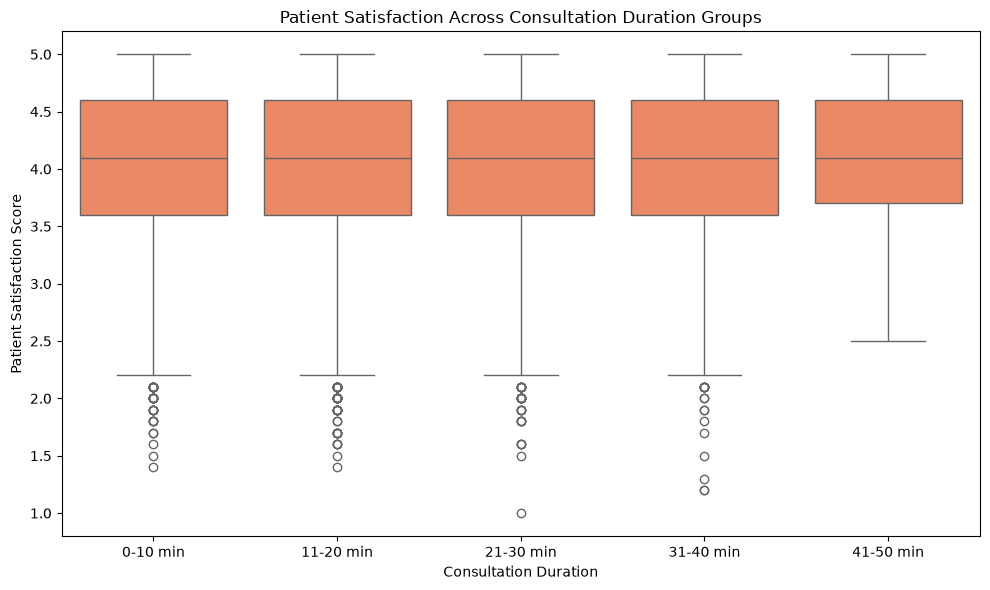

In [237]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=duration_df,
    x="duration_group",
    y="patient_satisfaction_score",
    color="coral"
)

plt.title("Patient Satisfaction Across Consultation Duration Groups")
plt.xlabel("Consultation Duration")
plt.ylabel("Patient Satisfaction Score")
plt.tight_layout()
plt.show()

### Business insight
1. correlation value is -0.00385 Almost zero correlation.This indicates virtually no linear relationship between consultation duration and patient satisfaction.
2. A longer consultation does not necessarily mean higher patient satisfaction.
3.A shorter consultation does not necessarily mean lower patient satisfaction.
4.Consultation duration alone does not explain patient satisfaction in this dataset.

In [239]:
#4.
correlation = completed_df["experience_years"].corr(completed_df["consultation_fee_y"])
print("Correlation:", correlation)

Correlation: 0.2767809853849189


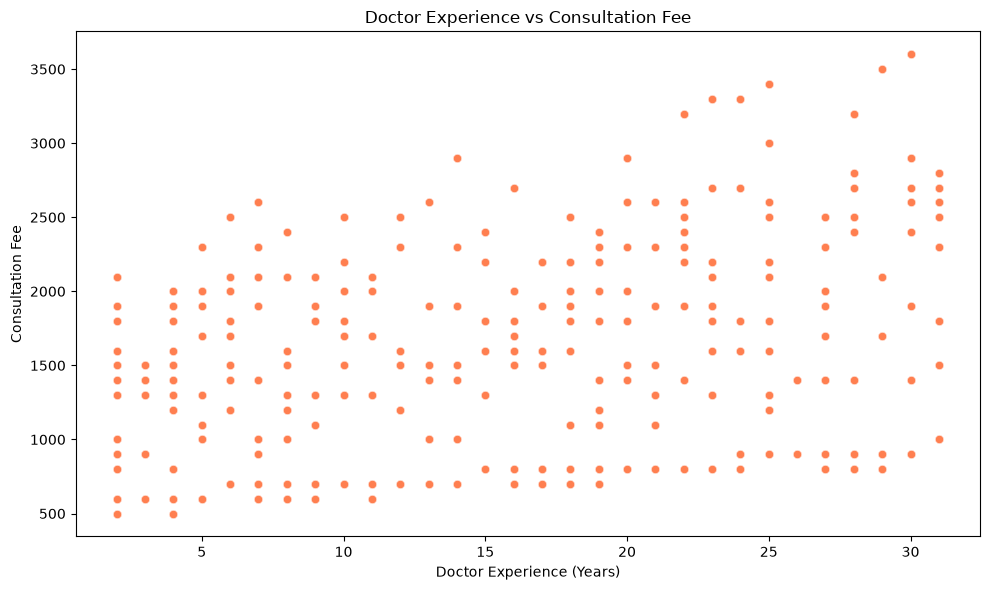

In [244]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=completed_df,
    x="experience_years",
    y="consultation_fee_y",
    color="coral",
    alpha=0.6
)

plt.title("Doctor Experience vs Consultation Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Consultation Fee")
plt.tight_layout()
plt.show()

In [242]:
#average consultation fee by experience
completed_df["experience_group"] = pd.cut(completed_df["experience_years"],
                                          bins=[0, 5, 10, 15, 20, float("inf")],
                                          labels=["0-5 Years", "6-10 Years", "11-15 Years", "16-20 Years", "Above 20 Years"])
experience_analysis = completed_df.groupby("experience_group", observed=False).agg(average_fee=("consultation_fee_y", "mean"),
                                                                                    total_appointments=("consultation_fee_y", "count")).reset_index()

experience_analysis

,experience_group,average_fee,total_appointments
0,0-5 Years,1321.567525,8893
1,6-10 Years,1441.959775,10491
2,11-15 Years,1494.389186,7842
3,16-20 Years,1528.105222,10112
4,Above 20 Years,1838.601773,17937


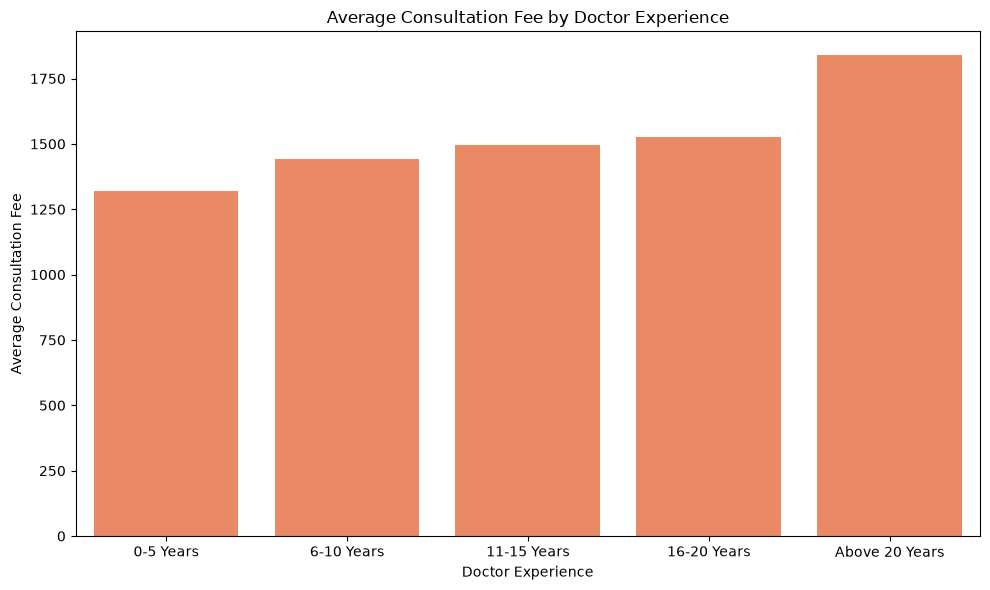

In [243]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=experience_analysis,
    x="experience_group",
    y="average_fee",
    color="coral"
)

plt.title("Average Consultation Fee by Doctor Experience")
plt.xlabel("Doctor Experience")
plt.ylabel("Average Consultation Fee")
plt.tight_layout()
plt.show()

### Key Business Insights
1. Doctors with more than 20 years of experience charge the highest average consultation fee of approximately ₹1,850.
2. Doctors with 0–5 years of experience charge the lowest average consultation fee of approximately ₹1,300.
3. The average consultation fee generally increases with doctor experience.
4. Doctors with more than 20 years of experience charge approximately ₹550 more per consultation than doctors with 0–5 years of experience.
5. This indicates that doctor experience may be an important factor influencing consultation fees.

### Why This Analysis Matters

It helps identify where the hospital is losing potential revenue through missed appointments.
It highlights opportunities to improve patient communication and appointment scheduling.
It helps management understand which services and locations contribute to financial performance.
It supports better planning of doctors, appointment slots and hospital resources.
It provides a clearer understanding of patient behaviour instead of relying only on overall appointment numbers.

### Conclusion
This analysis shows how appointment, patient, financial and operational data can be used together to identify improvement opportunities and support better hospital management and patient experience.
Rather than looking only at total appointments and revenue, this project also explores less obvious areas such as booking lead time, reminder effectiveness, previous no-show behaviour, patient demographics, waiting time and the relationship between consultation duration, satisfaction and doctor experience.
These additional comparisons help uncover patterns that may otherwise be overlooked and provide management with more useful information for decision-making.